# NN_L13_training_curves

**Training and validation L1 loss by epoch of the DNN (first monthly recalibration) and of N-BEATS, with early stopping at the best validation epoch.**

Neural Networks and Deep Learning (NN), Lecture 13 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L13/NN_L13_training_curves/NN_L13_training_curves.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

DNN best epoch = 14   [train.dnn_best_epoch]
N-BEATS best epoch = 2   [train.nb_best_epoch]


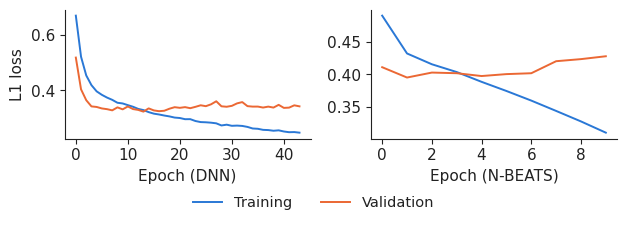

In [3]:
RES = REPO + 'lectures/L13/results/'
import json, urllib.request
src = RES + 'training_hist.json'
Hh = json.load(open(src)) if os.path.exists(src) else json.load(urllib.request.urlopen(src))
d, n = np.array(Hh['dnn']), np.array(Hh['nbeats'])
show('train.dnn_best_epoch', 'DNN best epoch', int(np.argmin(d[:, 1]) + 1))
show('train.nb_best_epoch', 'N-BEATS best epoch', int(np.argmin(n[:, 1]) + 1))
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.3))
for ax, h, lab in ((axs[0], d, 'Epoch (DNN)'), (axs[1], n, 'Epoch (N-BEATS)')):
    ax.plot(h[:, 0], color=PAL['train'], label='Training')
    ax.plot(h[:, 1], color=PAL['valid'], label='Validation')
    ax.set_xlabel(lab)
axs[0].set_ylabel('L1 loss')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('training_curves.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()